#GOLF SWING SEQUENCING
#Model Training and Validation

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import sys, os

PROJECT_DIR = "/content/drive/MyDrive/Colabs/GolfSwingSequencing"
sys.path.append(PROJECT_DIR)
os.chdir(PROJECT_DIR)

print("cwd:", os.getcwd())
print("files:", os.listdir(".")[:10])

cwd: /content/drive/MyDrive/Colabs/GolfSwingSequencing
files: ['.DS_Store', 'pubform.docx', 'videos_160', 'Golf Swing Sequencing with Deep Learning.docx', 'golfDatabaseDatasetVisualizationAndCleaning.py', 'GolfDB.csv', '__pycache__', 'README.md', 'GolfDB.pkl', 'golfDatabasePickle.py']


In [3]:
!pip -q install "tensorflow>=2.12"

In [4]:
!pip -q install opencv-python-headless


In [5]:
import Model
import GolfDataset as GD
from sklearn.model_selection import train_test_split
from tensorflow.keras import callbacks
import tensorflow as tf
import pandas as pd
import numpy as np
import Metrics as mt
from tensorflow.keras.metrics import SparseCategoricalAccuracy
import os
from datetime import datetime

print("Imports OK")

Imports OK


#PATH AND LOG SETUP

In [6]:
# Paths
BASE_DIR = os.getcwd()
FILENAME = os.path.join(BASE_DIR, "GolfDB.pkl")
VIDEO_DIR = "/content/videos_160"

print(VIDEO_DIR, FILENAME, BASE_DIR)

#logs
log_root = os.path.join(BASE_DIR, "logs")
os.makedirs(log_root, exist_ok=True)
run_id = datetime.now().strftime("%Y%m%d-%H%M%S")
log_dir = os.path.join(log_root, run_id)

# Models
model_root = os.path.join(BASE_DIR, "models")
os.makedirs(model_root, exist_ok=True)
filename_template = os.path.join(
    model_root,
    'weight_norm_loss_64_model_epoch_{epoch:02d}_val_event_auc_pr{val_event_auc_pr:.4f}.keras')

print("Paths, Models, and Logs OK")

/content/videos_160 /content/drive/MyDrive/Colabs/GolfSwingSequencing/GolfDB.pkl /content/drive/MyDrive/Colabs/GolfSwingSequencing
Paths, Models, and Logs OK


# HYPERPARAMETER AND CALLBACKS

In [7]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

# Hyperparameters and Constants
CLIP_LEN = 64
BATCH = 10
NUM_CLASSES = 9

#Callbacks
tensorboard_cb = callbacks.TensorBoard(
    log_dir=log_dir,
    histogram_freq=1,
    write_graph=True,
    write_images=False
)

checkpoint_callback = callbacks.ModelCheckpoint(
    filepath=filename_template,
    monitor='val_event_auc_pr',
    save_best_only=True,
    mode='max',
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_event_auc_pr',
    factor=0.2,
    patience=5,
    min_lr=0.001
)

print("Hyperparameters and Callbacks Good")

Hyperparameters and Callbacks Good


Copy videos to notebook
  - needed to stop CV2 from hanging when trying to access videos from drive directly

In [ ]:
# Copy Drive videos to local SSD
!rsync -a "/content/drive/MyDrive/Colabs/GolfSwingSequencing/videos_160/" "/content/videos_160/"

VIDEO_DIR = "/content/videos_160"
print("New VIDEO_DIR:", VIDEO_DIR)
print("Example files:", os.listdir(VIDEO_DIR)[:5])

New VIDEO_DIR: /content/videos_160
Example files: ['523.mp4', '749.mp4', '1214.mp4', '387.mp4', '635.mp4']


#TRAINING

In [ ]:
# train test split
df = pd.read_pickle(FILENAME)
train, test = train_test_split(df, test_size=.25)

print(train, test)

        id              player sex     club           view  slow  \
1348  1348  BEN ROETHLISBERGER   m   driver        face-on     0   
390    390     NICOLE CASTRALE   f   driver          other     0   
250    250     STEVEN BOWDITCH   m     iron  down-the-line     0   
180    180        MICHELLE WIE   f  fairway  down-the-line     0   
489    489       JUSTIN THOMAS   m   driver        face-on     1   
...    ...                 ...  ..      ...            ...   ...   
924    924         JUSTIN ROSE   m  fairway  down-the-line     1   
620    620          TOM LEHMAN   m     iron          other     0   
1216  1216         TIGER WOODS   m     iron  down-the-line     1   
1210  1210            LYDIA KO   f   driver        face-on     1   
990    990          JODI EWART   f   driver  down-the-line     1   

                                                events  \
1348  [0, 235, 250, 255, 263, 269, 272, 274, 289, 323]   
390   [0, 193, 210, 214, 222, 227, 230, 233, 250, 283]   
250      

In [ ]:
# Make Dataset Objects
train_obj = GD.GolfDataset(
    train,
    VIDEO_DIR,
    clip_len=CLIP_LEN,
    repeat_per_video=1
    )

test_obj = GD.GolfDataset(
    test,
    VIDEO_DIR,
    clip_len=CLIP_LEN,
    train=False,
    repeat_per_video=1)

steps_per_epoch = len(train_obj) // BATCH
validation_steps = len(test_obj)

print("Training Datasets and Splits Good")

frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbers received
frame numbe

In [8]:
# Build Model
model_256_units_32_clip = Model.build_LSTM(clip_len=CLIP_LEN, units=256)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
# Model Compile Boilerplate
model_256_units_32_clip.summary()
model_256_units_32_clip.compile(
    loss=mt.weighted_sparse_cce,
    metrics=[
            SparseCategoricalAccuracy(name="frame_accuracy"),
            mt.EventPrecision(),
            mt.EventRecall(),
            mt.EventAUC()
        ],
    optimizer='adam',
    run_eagerly=False
    )

Model: "LSTM_Golf"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Clip (InputLayer)               │ (None, 32, 160, 160,   │             0 │
│                                 │ 3)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_base (TimeDistributed)      │ (None, 32, 1280)       │     2,257,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Bi_Dir_LSTM (Bidirectional)     │ (None, 32, 512)        │     3,147,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 512)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (TimeDistributed)        │ (None, 32, 9)          │         4,617 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,410,377 (20.64 MB)

 Trainable params: 3,152,393 (12.03 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# Loading Model from saved verison
import Metrics as mt

model_path = "/content/drive/MyDrive/Colabs/GolfSwingSequencing/models/model_epoch_01_val_event_auc_pr0.2501.keras"

loaded_model = tf.keras.models.load_model(
    model_path,
    custom_objects={
        "weighted_sparse_cce": mt.weighted_sparse_cce,
        "EventPrecision": mt.EventPrecision,
        "EventRecall": mt.EventRecall,
        "EventAUC": mt.EventAUC,
    }
)

In [ ]:
# Logger Callback
from tensorflow.keras.callbacks import CSVLogger
logger_path = os.path.join(log_root, "CL128_U256_B2.csv")
csv_logger = CSVLogger(logger_path, append=True)

In [ ]:
# Training Loop
# Make new dataset each time to get randomized clips and augments for each
# epoch. Inefficient but didn't have time to fix.
for i in range(50):
  train_ds = GD.make_tf_ds(
    train_obj,
    batch_size=BATCH,
    clip_len=CLIP_LEN
    )

  test_ds = GD.make_tf_ds(
      test_obj,
      batch_size=1,
      augment=False,
      shuffle=False,
      clip_len=CLIP_LEN)

  print("Datasets Good")

  history= model_256_units_32_clip.fit(
      train_ds,
      validation_data=test_ds,
      epochs=1,
      verbose=1,
      steps_per_epoch=steps_per_epoch,
      validation_steps=validation_steps,
      callbacks=[tensorboard_cb, checkpoint_callback, csv_logger, reduce_lr],
      )

  print(f"epoch {i} complete")


Datasets Good
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 918ms/step - event_auc_pr: 0.0684 - event_precision: 0.0649 - event_recall: 0.5612 - frame_accuracy: 0.8982 - loss: 1.4049
Epoch 1: val_event_auc_pr improved from -inf to 0.05029, saving model to /content/drive/MyDrive/Colabs/GolfSwingSequencing/models/128_model_epoch_01_val_event_auc_pr0.0503.keras
105/105 ━━━━━━━━━━━━━━━━━━━━ 306s 2s/step - event_auc_pr: 0.0684 - event_precision: 0.0649 - event_recall: 0.5621 - frame_accuracy: 0.8985 - loss: 1.4035 - val_event_auc_pr: 0.0503 - val_event_precision: 0.0515 - val_event_recall: 0.3920 - val_frame_accuracy: 0.9620 - val_loss: 0.7537 - learning_rate: 0.0010
epoch 0 complete
Datasets Good
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 943ms/step - event_auc_pr: 0.0789 - event_precision: 0.0739 - event_recall: 0.6809 - frame_accuracy: 0.9392 - loss: 1.0719
Epoch 1: val_event_auc_pr improved from 0.05029 to 0.06336, saving model to /content/drive/MyDrive/Colabs/GolfSwingSequencing/models/128_model_epoch_01_val_e

In [ ]:
# Reset learning rate after model reaches plateau
new_lr = 0.0001
model_256_units_32_clip.optimizer.learning_rate = new_lr

#NEW MODEL - CL32 B10 Loss: Focal

In [ ]:
!pip install focal-loss

In [ ]:
model_256_units_32_clip_focal = Model.build_LSTM(clip_len=CLIP_LEN, units=256)

In [ ]:
from focal_loss import SparseCategoricalFocalLoss

alpha = [2.0] + [3.0]*8
gamma = 1.0

focal_loss = SparseCategoricalFocalLoss(
    gamma=gamma,
    class_weight=alpha,
    from_logits=False
)

In [ ]:
model_256_units_32_clip_focal.compile(
    loss=focal_loss,
    metrics=[
            SparseCategoricalAccuracy(name="frame_accuracy"),
            mt.EventPrecision(),
            mt.EventRecall(),
            mt.EventAUC()
        ],
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    run_eagerly=False
    )

In [ ]:
from tensorflow.keras.callbacks import CSVLogger
logger_path = os.path.join(log_root, "CL32_Focal_U256_B10_Reset.csv")
csv_logger = CSVLogger(logger_path, append=True)

In [ ]:
for i in range(10):
  train_ds = GD.make_tf_ds(
    train_obj,
    batch_size=BATCH,
    clip_len=CLIP_LEN
    )

  test_ds = GD.make_tf_ds(
      test_obj,
      batch_size=1,
      augment=False,
      shuffle=False,
      clip_len=CLIP_LEN)

  print("Datasets Good")

  history= model_256_units_32_clip_focal.fit(
      train_ds,
      validation_data=test_ds,
      epochs=1,
      verbose=1,
      steps_per_epoch=steps_per_epoch,
      validation_steps=validation_steps,
      callbacks=[tensorboard_cb, checkpoint_callback, csv_logger, reduce_lr],
      )

  print(f"epoch {i+1} complete\n")

Datasets Good
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 964ms/step - event_auc_pr: 0.2387 - event_precision: 0.1322 - event_recall: 0.6121 - frame_accuracy: 0.9394 - loss: 0.4022
Epoch 1: val_event_auc_pr did not improve from 0.27384
105/105 ━━━━━━━━━━━━━━━━━━━━ 310s 2s/step - event_auc_pr: 0.2388 - event_precision: 0.1323 - event_recall: 0.6125 - frame_accuracy: 0.9394 - loss: 0.4022 - val_event_auc_pr: 0.2454 - val_event_precision: 0.1622 - val_event_recall: 0.5224 - val_frame_accuracy: 0.9635 - val_loss: 0.2757 - learning_rate: 1.0000e-04
epoch 1 complete

Datasets Good
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 973ms/step - event_auc_pr: 0.2584 - event_precision: 0.1389 - event_recall: 0.6427 - frame_accuracy: 0.9369 - loss: 0.3769
Epoch 1: val_event_auc_pr did not improve from 0.27384
105/105 ━━━━━━━━━━━━━━━━━━━━ 155s 1s/step - event_auc_pr: 0.2585 - event_precision: 0.1390 - event_recall: 0.6430 - frame_accuracy: 0.9369 - loss: 0.3770 - val_event_auc_pr: 0.2071 - val_event_precision: 0.1429 - val_eve

KeyboardInterrupt: 

#RETRAINING BEST 64 CLIP MODEL

In [ ]:
# Hyperparameters and Constants
import Metrics as mt

CLIP_LEN = 64

model_path = "/content/drive/MyDrive/Colabs/GolfSwingSequencing/models/model_epoch_01_val_event_auc_pr0.3136.keras"

loaded_model = tf.keras.models.load_model(
    model_path,
    custom_objects={
        "weighted_sparse_cce": mt.weighted_sparse_cce,
        "EventPrecision": mt.EventPrecision,
        "EventRecall": mt.EventRecall,
        "EventAUC": mt.EventAUC,
    }
)

In [ ]:
from tensorflow.keras.callbacks import CSVLogger
logger_path = os.path.join(log_root, "M256_B5.csv")
csv_logger = CSVLogger(logger_path, append=True)

In [ ]:
new_lr = 0.0001
loaded_model.optimizer.learning_rate = new_lr

In [ ]:
for i in range(20):
  train_ds = GD.make_tf_ds(
    train_obj,
    batch_size=BATCH,
    clip_len=CLIP_LEN
    )

  test_ds = GD.make_tf_ds(
      test_obj,
      batch_size=1,
      augment=False,
      shuffle=False,
      clip_len=CLIP_LEN)

  print("Datasets Good")

  history= loaded_model.fit(
      train_ds,
      validation_data=test_ds,
      epochs=1,
      verbose=1,
      steps_per_epoch=steps_per_epoch,
      validation_steps=validation_steps,
      callbacks=[tensorboard_cb, checkpoint_callback, csv_logger, reduce_lr],
      )

  print(f"epoch {i+1} complete\n")

Datasets Good
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - event_auc_pr: 0.4041 - event_precision: 0.1812 - event_recall: 0.7473 - frame_accuracy: 0.9195 - loss: 0.4989
Epoch 1: val_event_auc_pr did not improve from 0.32082
105/105 ━━━━━━━━━━━━━━━━━━━━ 299s 3s/step - event_auc_pr: 0.4041 - event_precision: 0.1813 - event_recall: 0.7473 - frame_accuracy: 0.9194 - loss: 0.4990 - val_event_auc_pr: 0.3000 - val_event_precision: 0.2072 - val_event_recall: 0.5572 - val_frame_accuracy: 0.9497 - val_loss: 0.4701 - learning_rate: 1.0000e-04
epoch 1 complete

Datasets Good
 82/105 ━━━━━━━━━━━━━━━━━━━━ 46s 2s/step - event_auc_pr: 0.3997 - event_precision: 0.1763 - event_recall: 0.7514 - frame_accuracy: 0.9179 - loss: 0.5131

KeyboardInterrupt: 

In [ ]:
new_lr = 0.00001
loaded_model.optimizer.learning_rate = new_lr

In [ ]:
for i in range(20):
  train_ds = GD.make_tf_ds(
    train_obj,
    batch_size=BATCH,
    clip_len=CLIP_LEN
    )

  test_ds = GD.make_tf_ds(
      test_obj,
      batch_size=1,
      augment=False,
      shuffle=False,
      clip_len=CLIP_LEN)

  print("Datasets Good")

  history= loaded_model.fit(
      train_ds,
      validation_data=test_ds,
      epochs=1,
      verbose=1,
      steps_per_epoch=steps_per_epoch,
      validation_steps=validation_steps,
      callbacks=[tensorboard_cb, checkpoint_callback, csv_logger, reduce_lr],
      )

  print(f"epoch {i+1} complete\n")

Datasets Good
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - event_auc_pr: 0.4129 - event_precision: 0.1792 - event_recall: 0.7481 - frame_accuracy: 0.9167 - loss: 0.5119
Epoch 1: val_event_auc_pr did not improve from 0.32082
105/105 ━━━━━━━━━━━━━━━━━━━━ 304s 3s/step - event_auc_pr: 0.4130 - event_precision: 0.1793 - event_recall: 0.7482 - frame_accuracy: 0.9167 - loss: 0.5119 - val_event_auc_pr: 0.3033 - val_event_precision: 0.1977 - val_event_recall: 0.5599 - val_frame_accuracy: 0.9494 - val_loss: 0.4576 - learning_rate: 1.0000e-05
epoch 1 complete

Datasets Good
105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - event_auc_pr: 0.3980 - event_precision: 0.1802 - event_recall: 0.7505 - frame_accuracy: 0.9187 - loss: 0.5013
Epoch 1: val_event_auc_pr did not improve from 0.32082
105/105 ━━━━━━━━━━━━━━━━━━━━ 302s 3s/step - event_auc_pr: 0.3982 - event_precision: 0.1803 - event_recall: 0.7506 - frame_accuracy: 0.9186 - loss: 0.5013 - val_event_auc_pr: 0.3167 - val_event_precision: 0.2113 - val_event_rec

#VALIDATION

In [ ]:
# Best 64 clip model for validation
# Ignore the name of the path. I made a mistake when saving
# This uses the same custom weighted loss sparse crossentropy loss

import Metrics as mt
import GolfDataset as GD

model_path = "/content/drive/MyDrive/Colabs/GolfSwingSequencing/models/weight_norm_loss_64_model_epoch_01_val_event_auc_pr0.3311.keras"

loaded_model = tf.keras.models.load_model(
    model_path,
    custom_objects={
        "weighted_sparse_cce": mt.weighted_sparse_cce,
        "EventPrecision": mt.EventPrecision,
        "EventRecall": mt.EventRecall,
        "EventAUC": mt.EventAUC,
    }
)

In [ ]:
val_obj = GD.FullVideoGolfDataset(
    test,
    VIDEO_DIR,
    )

In [ ]:
val_ds = GD.make_full_video_tf_ds(val_obj)

In [ ]:
PCE = mt.compute_dataset_pce_FIXED(loaded_model, val_ds, clip_len=64)

(0.5932142857142857, array([0.08857143, 0.66285714, 0.64857143, 0.53142857, 0.86      ,
       0.89428571, 0.91714286, 0.14285714]))


In [ ]:
f = open("PCE_Results.txt", "w")
f.write(f"{PCE}")
f.close()

#Test Video

In [ ]:
import Metrics as mt
import GolfDataset as GD

model_path = "/content/drive/MyDrive/Colabs/GolfSwingSequencing/models/weight_norm_loss_64_model_epoch_01_val_event_auc_pr0.3311.keras"

loaded_model = tf.keras.models.load_model(
    model_path,
    custom_objects={
        "weighted_sparse_cce": mt.weighted_sparse_cce,
        "EventPrecision": mt.EventPrecision,
        "EventRecall": mt.EventRecall,
        "EventAUC": mt.EventAUC,
    }
)

In [ ]:
import TestVideo as tv
import importlib

importlib.reload(tv)

test_video = tv.TestVideo(
    "/content/drive/MyDrive/Colabs/GolfSwingSequencing/IMG_3226.MOV",
    target_size=(160, 160)) # Specify target size for cropping

Moviepy - Building video /content/drive/MyDrive/Colabs/GolfSwingSequencing/IMG_3226_resized.mp4.
MoviePy - Writing audio in IMG_3226_resizedTEMP_MPY_wvf_snd.mp3


MoviePy - Done.
Moviepy - Writing video /content/drive/MyDrive/Colabs/GolfSwingSequencing/IMG_3226_resized.mp4



t:  99%|█████████▉| 184/186 [00:03<00:00, 55.41it/s, now=None]WARNING:py.warnings:/usr/local/lib/python3.12/dist-packages/moviepy/video/io/ffmpeg_reader.py:123: UserWarning: Warning: in file /content/drive/MyDrive/Colabs/GolfSwingSequencing/IMG_3226.MOV, 6220800 bytes wanted but 0 bytes read,at frame 185/186, at time 6.17/6.17 sec. Using the last valid frame instead.
  warnings.warn("Warning: in file %s, "%(self.filename)+



Moviepy - Done !
Moviepy - video ready /content/drive/MyDrive/Colabs/GolfSwingSequencing/IMG_3226_resized.mp4
Video resized
Loaded frames shape: (185, 160, 160, 3)


In [ ]:
test_video.frames

array([[[[ 0.5294118 ,  0.43529415,  0.21568632],
         [ 0.5137255 ,  0.41960788,  0.20000005],
         [ 0.5137255 ,  0.41960788,  0.20000005],
         ...,
         [ 0.6627451 ,  0.24705887,  0.01176476],
         [ 0.75686276,  0.30196083,  0.06666672],
         [ 0.8352941 ,  0.3803922 ,  0.14509809]],

        [[ 0.5294118 ,  0.43529415,  0.21568632],
         [ 0.5137255 ,  0.41960788,  0.20000005],
         [ 0.52156866,  0.427451  ,  0.20784318],
         ...,
         [ 0.6627451 ,  0.24705887,  0.01176476],
         [ 0.7490196 ,  0.2941177 ,  0.05882359],
         [ 0.8352941 ,  0.3803922 ,  0.14509809]],

        [[ 0.56078434,  0.4666667 ,  0.24705887],
         [ 0.5686275 ,  0.47450984,  0.254902  ],
         [ 0.5764706 ,  0.48235297,  0.26274514],
         ...,
         [ 0.6862745 ,  0.24705887,  0.0196079 ],
         [ 0.75686276,  0.30196083,  0.06666672],
         [ 0.8352941 ,  0.3803922 ,  0.14509809]],

        ...,

        [[-0.32549018, -0.03529412,  0

In [ ]:
preds = tv.compute_event_frames(loaded_model, test_video.frames)

In [ ]:
print(preds)

[  6  64  66  24  86 183 184 138]


In [ ]:
type(preds)

numpy.ndarray

In [ ]:
f = open("Pred_Frame_Results.txt", "w")
f.write(f"{preds}")
f.close()

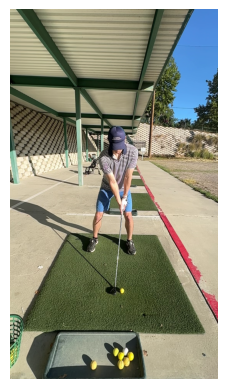

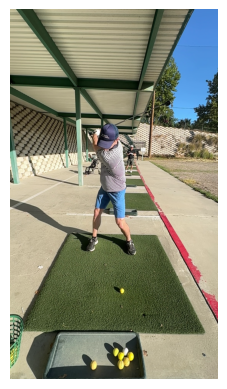

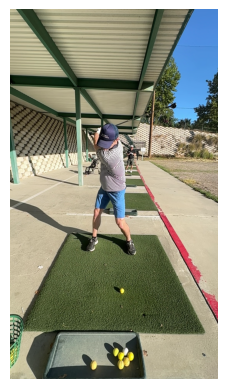

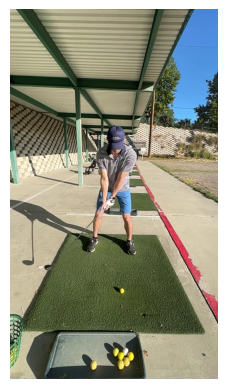

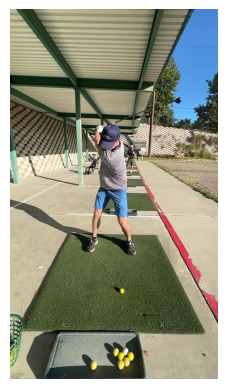

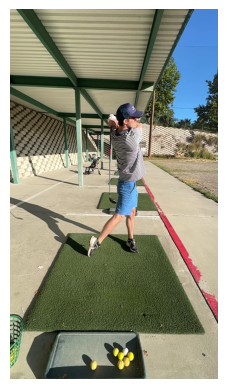

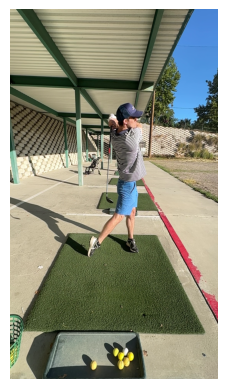

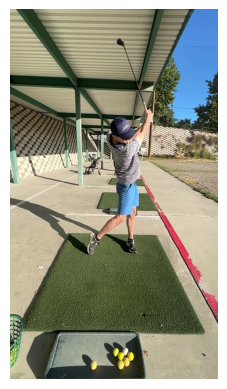

In [ ]:
import cv2
import matplotlib.pyplot as plt

test_video_path = "/content/drive/MyDrive/Colabs/GolfSwingSequencing/IMG_3226.MOV"

cap = cv2.VideoCapture(test_video_path)

if not cap.isOpened():
    print("Error opening video file")

for i, idx in enumerate(preds):
  cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
  ret, frame = cap.read()

  if not ret:
    break

  frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
  plt.imshow(frame)
  plt.axis('off') # Add this line to turn off axes
  plt.show()

cap.release()

#Confusion Matrix

In [ ]:
!pip install scikit-learn

In [ ]:
val_obj = GD.FullVideoGolfDataset(
    test,
    VIDEO_DIR,
    )

In [ ]:
val_ds = GD.make_full_video_tf_ds(val_obj)

In [ ]:
import TestVideo as tv
import importlib

importlib.reload(tv)

event_preds = []
true_labels = []

for frames, labels in val_ds:
  event_preds.append(tv.compute_all_frame_predictions(loaded_model, frames))
  true_labels.append(labels)

Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexes Added
Indexe

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

event_preds = tf.concat(event_preds, axis=0)
true_labels = tf.concat(true_labels, axis=0)

cm = confusion_matrix(true_labels, event_preds, labels=range(9))
print(cm)

[[97249     0   121   168   145   217   251   248     0]
 [  350     0     0     0     0     0     0     0     0]
 [  301     0    49     0     0     0     0     0     0]
 [  277     0     0    73     0     0     0     0     0]
 [  278     0     0     0    72     0     0     0     0]
 [  180     0     0     0     0   170     0     0     0]
 [  164     0     0     0     0     1   185     0     0]
 [  186     0     0     0     0     0     0   164     0]
 [  350     0     0     0     0     0     0     0     0]]


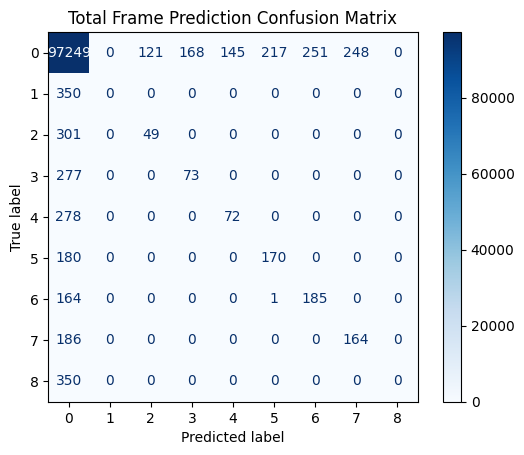

In [ ]:
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay(
    cm,
    display_labels=range(9),
)

disp.plot(cmap=plt.cm.Blues)
disp.ax_.set_title("Total Frame Prediction Confusion Matrix")
plt.show()